# 3. Run-level hypothesis tests (RQ1, RQ3, and η for RQ2)

The procedure of report Section 4.5, implemented in `stats.analyse`.

1. **Check assumptions.** Shapiro-Wilk per strategy, median-centred Levene across strategies.
   If normality cannot be assumed, the checks are repeated on log values.
2. **Omnibus test.** One-way ANOVA (equal variances) or Welch's ANOVA when normal,
   Kruskal-Wallis otherwise. α = 0.05.
3. **Pairwise comparisons, only when the omnibus test is significant.** Student's or Welch's
   t-test with Cohen's d, or Mann-Whitney U with Cliff's δ. Differences are in original
   units and as % of the second strategy.

Variables that are constant within a strategy are only descriptively reported on.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

import experiment_data as data
import stats
import style

style.apply()
pd.set_option("display.precision", 3)
runs = data.load_runs()

## 3.1 Assumptions and omnibus tests

In [2]:
results = {variable: stats.analyse(runs, variable) for variable in data.RUN_VARIABLES}

def summary(results):
    rows = []
    for variable, r in results.items():
        rows.append({"variable": data.RUN_VARIABLES[variable],
                     "transform": r.get("transform", ""),
                     **{f"Shapiro p {s}": r.get("shapiro_p", {}).get(s) for s in data.STRATEGIES},
                     "Levene p": r.get("levene_p"), "test": r["test"], "p": r["p"]})
    return pd.DataFrame(rows).set_index("variable")

summary(results)

,transform,Shapiro p S,Shapiro p L,Shapiro p R,Levene p,test,p
variable,,,,,,,
Total energy E (J),none,7.572e-01,0.119,8.603e-01,5.141e-01,one-way ANOVA,3.433e-191
Energy per query E/N (J/query),none,7.572e-01,0.119,8.603e-01,5.141e-01,one-way ANOVA,3.433e-191
Energy per output token E/K (J/token),none,7.572e-01,0.119,8.603e-01,9.900e-02,one-way ANOVA,2.083e-211
Energy efficiency η = C/E (correct per kJ),none,7.644e-01,0.125,8.596e-01,2.678e-04,Welch's ANOVA,1.414e-94
Total inference time T (s),none,2.115e-02,0.128,6.308e-02,5.993e-01,Kruskal-Wallis,6.312e-18
Mean query latency (s),none,4.848e-01,0.331,4.257e-01,3.517e-01,one-way ANOVA,3.361e-225
95th-percentile query latency (s),none,3.718e-05,0.073,6.792e-04,1.128e-04,Kruskal-Wallis,6.594e-18
Mean utilization GPU 0 (%),,NaN,NaN,NaN,NaN,descriptive only (constant within a strategy),NaN
Mean utilization GPU 1 (%),,NaN,NaN,NaN,NaN,descriptive only (constant within a strategy),NaN


**Q-Q plots** for energy per query. Points are normally distributed runs.

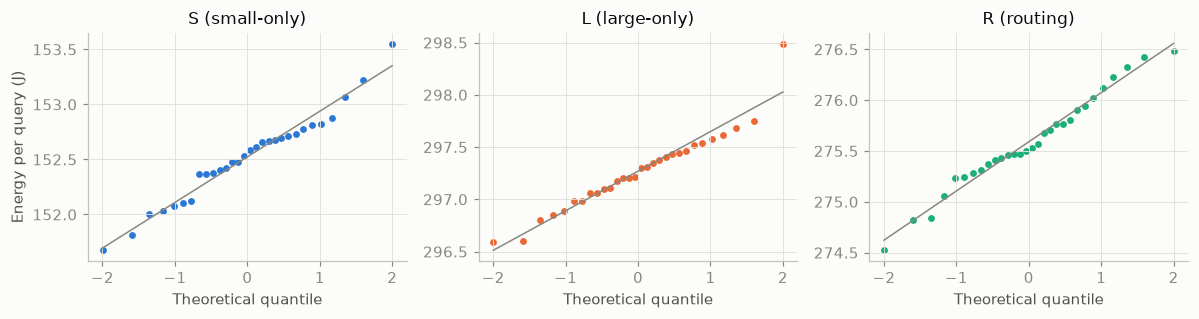

In [3]:
from scipy.stats import probplot

fig, axes = plt.subplots(1, 3, figsize=(11, 3))

for ax, strategy in zip(axes, data.STRATEGIES):
    (theoretical, ordered), (slope, intercept, _) = probplot(
        runs.loc[runs["strategy"] == strategy, "energy_per_query_j"])
    ax.scatter(theoretical, ordered, s=12, color=style.COLORS[strategy])
    ax.plot(theoretical, slope * theoretical + intercept, color=style.MUTED, linewidth=1)
    ax.set_title(style.label(strategy))
    ax.set_xlabel("Theoretical quantile")
    
axes[0].set_ylabel("Energy per query (J)")
plt.tight_layout()

## 3.2 Pairwise comparisons

In [4]:
pairwise = pd.concat({data.RUN_VARIABLES[v]: r["pairwise"]
                      for v, r in results.items() if r["pairwise"] is not None})
pairwise.droplevel(1).set_index("comparison", append=True)

mean_difference  \
                                           comparison                    
Total energy E (J)                         S - L            -72372.979   
                                           S - R            -61533.119   
                                           L - R             10839.860   
Energy per query E/N (J/query)             S - L              -144.746   
                                           S - R              -123.066   
                                           L - R                21.680   
Energy per output token E/K (J/token)      S - L                -3.165   
                                           S - R                -1.931   
                                           L - R                 1.234   
Energy efficiency η = C/E (correct per kJ) S - L                 0.504   
                                           S - R                 0.736   
                                           L - R                 0.232   
Total inference time T (s)                 S - L              -283.144   
                                           S - R              -192.051   
                                           L - R                91.092   
Mean query latency (s)                     S - L                -0.566   
                                           S - R                -0.383   
                                           L - R                 0.183   
95th-percentile query latency (s)          S - L                -0.935   
                                           S - R                -0.870   
                                           L - R                 0.066   
Peak host memory (MiB)                     S - L               -11.508   
                                           S - R             -7787.270   
                                           L - R             -7775.762   

                                                       percent_vs_second  \
                                           comparison                      
Total energy E (J)                         S - L                 -48.692   
                                           S - R                 -44.656   
                                           L - R                   7.867   
Energy per query E/N (J/query)             S - L                 -48.692   
                                           S - R                 -44.656   
                                           L - R                   7.867   
Energy per output token E/K (J/token)      S - L                 -70.561   
                                           S - R                 -59.391   
                                           L - R                  37.944   
Energy efficiency η = C/E (correct per kJ) S - L                  17.582   
                                           S - R                  27.925   
                                           L - R                   8.797   
Total inference time T (s)                 S - L                 -45.175   
                                           S - R                 -35.852   
                                           L - R                  17.005   
Mean query latency (s)                     S - L                 -45.183   
                                           S - R                 -35.792   
                                           L - R                  17.131   
95th-percentile query latency (s)          S - L                 -41.595   
                                           S - R                 -39.842   
                                           L - R                   3.002   
Peak host memory (MiB)                     S - L                  -0.095   
                                           S - R                 -39.126   
                                           L - R                 -39.068   

                                                                 test  \
                                           comparison                   
Total e

## 3.3 Sensitivity: without the first run

The first run of the experiment is a hot start (notebook 2 notes). It stays in the main analysis,
but repeating the tests without it shows whether it drives any conclusion.

In [5]:
without_first = runs[runs["order"] > 0]
summary({v: stats.analyse(without_first, v) for v in data.RUN_VARIABLES})

,transform,Shapiro p S,Shapiro p L,Shapiro p R,Levene p,test,p
variable,,,,,,,
Total energy E (J),none,6.676e-01,0.119,8.603e-01,4.062e-01,one-way ANOVA,5.511e-190
Energy per query E/N (J/query),none,6.676e-01,0.119,8.603e-01,4.062e-01,one-way ANOVA,5.511e-190
Energy per output token E/K (J/token),none,6.676e-01,0.119,8.603e-01,5.028e-02,one-way ANOVA,2.411e-209
Energy efficiency η = C/E (correct per kJ),none,6.526e-01,0.125,8.596e-01,6.221e-04,Welch's ANOVA,3.756e-95
Total inference time T (s),none,1.202e-02,0.128,6.308e-02,6.513e-01,Kruskal-Wallis,9.873e-18
Mean query latency (s),none,3.470e-01,0.331,4.257e-01,4.195e-01,one-way ANOVA,8.340e-223
95th-percentile query latency (s),none,5.910e-05,0.073,6.792e-04,4.121e-05,Kruskal-Wallis,1.032e-17
Mean utilization GPU 0 (%),,NaN,NaN,NaN,NaN,descriptive only (constant within a strategy),NaN
Mean utilization GPU 1 (%),,NaN,NaN,NaN,NaN,descriptive only (constant within a strategy),NaN


## 3.4 Descriptive only: constant within a strategy

In [6]:
constant = [v for v, r in results.items() if r["pairwise"] is None and pd.isna(r["p"])]
runs.groupby("strategy", observed=True)[constant].agg(["mean", "std"])

gpu0_util_pct        gpu1_util_pct        gpu_memory_peak_mib     
                  mean    std          mean    std                mean  std
strategy                                                                   
S                0.000  0.000        85.018  0.101              3372.0  0.0
L               93.238  0.124         0.000  0.000              7378.0  0.0
R               71.931  0.108        20.079  0.099              9838.0  0.0

**Notes**

- **Every testable variable differs between strategies, and every pair differs,** except peak
  host memory between S and L, which barely differ (Cliff's δ = −0.08). This is expected with such
  a small within-strategy spread.
- **The effect sizes are big.** Cliff's δ = ±1 means every run of one strategy lies
  above every run of the other. Cohen's d ranges from about 50 to over 800. These numbers
  show that the groups do not overlap; the mean differences and % columns show how large the
  differences are in practice.
- **The practical result for RQ1.** S uses about half the energy of L (−49%). R saves only
  about 7% compared with L, while sending 59% of questions to the large model. Notebook 4
  tries to find why.
- **η (correct answers per kJ) ranks R last.** L is about 9% more efficient than R, and S
  about 18% more than L. Routing gives up 63 correct answers (12.6 pp) while saving only 7% energy,
  so it ends up as the least efficient strategy.
- **Normality.** The energy variables are normal in every strategy and use one-way ANOVA
  (η uses Welch's ANOVA, its variances differ). Time, p95 latency and peak host memory fail the
  normality check and use Kruskal-Wallis; the log transform does not fix them.
  - Without the first run, every test and conclusion stays the same.
- **Peak host memory is not a reliable measure of the strategies.** EnergiBridge records the
  memory used by the whole machine, so it also reflects the server's state; R's peak (about 19.9 GB)
  is much higher than in the earlier 100-question experiment (about 12.4 GB) on the same code.
- **The utilization variables are seemingly "constant" because of one strategy.** For example,
  GPU 0 is unused under S and reads exactly 0%. The report's rule (non-zero variance in
  every group) then makes them descriptive. We could instead compare only the strategies
  that use that GPU?
- **The tests assume independent runs.** The small autocorrelation found in notebook 2 makes
  the p-values a bit optimistic. Considering their size, this doesn't change any conclusion,
  but it should be mentioned in threats to validity.